In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# gold_price_model.py(실서비스)와 동일한 데이터(global_quarterly_data_260511/260604.xlsx)를
# 미리 추출해둔 data/gold CSV를 직접 쓴다 (전체 이력 비대조 결과 불일치 0건, 확인됨).
# gold_major_variables.csv가 이미 feature engineering 끝난 X 6개 컴럼(X1_l1 등)을 담고
# 있어서, 원본 xlsx에서 다시 feature engineering할 필요 없음.
GOLD_DATA_DIR = "../../data/gold"

x_actual = pd.read_csv(f"{GOLD_DATA_DIR}/gold_major_variables.csv", encoding="utf-8-sig", float_precision="round_trip")
x_actual = x_actual.dropna(subset=["quarter"])

price = pd.read_csv(f"{GOLD_DATA_DIR}/gold_price.csv", encoding="utf-8-sig", float_precision="round_trip")
price.columns = ["quarter", "gold", "gold_pred"]  # 분기 / 실제가 / 예측가
price = price.dropna(subset=["quarter"])[["quarter", "gold"]]

df = x_actual.merge(price, on="quarter", how="outer")
df["qdate"] = pd.PeriodIndex(df["quarter"], freq="Q").to_timestamp()
df = df.sort_values("qdate").reset_index(drop=True)

# Y: 금 가격 YoY 로그 변화율. (X는 gold_major_variables.csv에 이미 다 들어있음)
df["log_gold"] = np.log(df["gold"])
df["yoy_log_gold"] = df["log_gold"] - df["log_gold"].shift(4)

Y = "yoy_log_gold"

In [2]:
df

,quarter,X1_l1,X2,X3_l1,X4,X5_l1,X6_l1,gold,qdate,log_gold,yoy_log_gold
0,2010Q1,NaN,NaN,NaN,NaN,NaN,NaN,1109.115079,2010-01-01,7.011318,NaN
1,2010Q2,NaN,NaN,NaN,NaN,NaN,0.617866,1196.741803,2010-04-01,7.087358,NaN
2,2010Q3,NaN,NaN,NaN,NaN,NaN,0.625629,1226.750000,2010-07-01,7.112124,NaN
3,2010Q4,NaN,NaN,NaN,NaN,NaN,0.618217,1366.782258,2010-10-01,7.220215,NaN
4,2011Q1,NaN,-0.003598,79.150503,0.108259,NaN,0.619359,1386.265873,2011-01-01,7.234369,0.223051
...,...,...,...,...,...,...,...,...,...,...,...
59,2024Q4,211.734949,-0.001808,942.575656,0.047114,0.072321,0.579302,2663.376613,2024-10-01,7.887350,0.300806
60,2025Q1,86.881128,0.001985,1092.371302,0.043614,0.068064,0.585184,2859.619048,2025-01-01,7.958444,0.323238
61,2025Q2,352.345805,-0.000377,1016.103165,0.053659,0.049581,0.585177,3280.352459,2025-04-01,8.095706,0.338580
62,2025Q3,211.364383,0.000955,983.835589,0.049294,0.047423,0.570801,3456.543846,2025-07-01,8.148024,0.334315


# NEW VERSION

In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

def forecast_tvp_multistep(
    df: pd.DataFrame,
    date_col: str,
    train_end_date: str,
    y_col: str,
    x_cols: list[str],
    standardize_x: bool = True,
    maxiter: int = 3000
) -> pd.DataFrame:
    """
    통합 데이터프레임과 train_end_date를 받아, Train 구간 파라미터로 학습한 뒤 
    Test 구간(train_end_date 이후)의 Feature(X)를 활용하여 Multi-step Dynamic 예측을 수행합니다.

    Parameters:
    ----------
    df : pd.DataFrame
        Train 및 Test 기간 데이터가 모두 포함된 통합 데이터프레임 (날짜 오름차순 정렬 필요)
    date_col : str
        날짜/분기 컬럼명 (예: 'qdate' 또는 'quarter')
    train_end_date : str or pd.Timestamp
        Train 기간의 마지막 날짜 (예: '2024-12-31' 또는 '2024Q4')
    y_col : str
        타겟 변수(Y) 컬럼명
    x_cols : list[str]
        외생 설명 변수(X) 컬럼명 리스트
    standardize_x : bool, default True
        Train 기준 통계량(mean, std)으로 X 변수 표준화 여부 (Data Leakage 방지)
    maxiter : int, default 3000
        최적화 최대 반복 횟수

    Returns:
    -------
    pd.DataFrame
        train_end_date 이후(Test 구간) 데이터에 1~N step 예측값('pred_multistep')이 추가된 데이터프레임
    """
    data = df.copy().sort_values(by=date_col).reset_index(drop=True)

    # 1. Train / Test 구간 분리 인덱스 탐색
    # train_end_date 이하인 구간까지를 Train으로 설정
    train_mask = data[date_col] <= pd.to_datetime(train_end_date)
    test_start_idx = train_mask.sum()

    if test_start_idx == 0:
        raise ValueError(f"train_end_date ({train_end_date}) 이전 데이터가 존재하지 않습니다.")
    if test_start_idx >= len(data):
        raise ValueError(f"train_end_date ({train_end_date}) 이후의 Test 구간 데이터가 존재하지 않습니다.")

    tr_data = data.iloc[:test_start_idx].copy()

    # 2. Train 기준 X 변수 표준화 (Data Leakage 방지)
    mu, sd = None, None
    if standardize_x:
        mu = tr_data[x_cols].mean()
        sd = tr_data[x_cols].std(ddof=0).replace(0, 1.0)
        
        # 전체 데이터에 Train의 mu, sd 적용
        data[x_cols] = (data[x_cols] - mu) / sd
        tr_data[x_cols] = (tr_data[x_cols] - mu) / sd

    # ---------------------------------------------------------
    # [Step 1. Train] Train 구간 데이터만 사용하여 TVP SARIMAX 피팅
    # ---------------------------------------------------------
    exog_tr = np.column_stack([np.ones(len(tr_data)), tr_data[x_cols].astype(float).to_numpy()])
    mod_tr = sm.tsa.SARIMAX(
        endog=tr_data[y_col].astype(float).to_numpy(),
        exog=exog_tr,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    
    try:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter)
    except Exception:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter * 2, method="powell")

    # ---------------------------------------------------------
    # [Step 2. Inference] 학습된 파라미터를 전체 데이터에 고정(filter) 후 Dynamic 예측
    # ---------------------------------------------------------
    exog_full = np.column_stack([np.ones(len(data)), data[x_cols].astype(float).to_numpy()])
    mod_full = sm.tsa.SARIMAX(
        endog=data[y_col].astype(float).to_numpy(),
        exog=exog_full,
        order=(0, 0, 0),
        trend="n",
        time_varying_regression=True,
        mle_regression=False,
    )
    # Train에서 피팅된 파라미터(res_tr.params)만 주입하여 칼만 필터링 수행
    res_f = mod_full.filter(res_tr.params)

    # dynamic=test_start_idx: Test 시작점 이후부터 실제 Y 실측치 업데이트를 끊고,
    # 모델 자신의 이전 단계 예측값(\hat{Y})을 시차항(AR)으로 재귀적 반영하여 미래 N-step을 연속 예측함
    start_i = test_start_idx
    end_i = len(data) - 1
    pred = res_f.get_prediction(start=start_i, end=end_i, dynamic=True)
    yhat = np.asarray(pred.predicted_mean)

    # 3. Test 기간 결과 데이터프레임 구성 및 반환
    # 원본 Scale 복원을 대비해 원래 입력 데이터 기준으로 출력 추출
    test_out = df.iloc[test_start_idx:].copy().reset_index(drop=True)
    test_out["pred_multistep"] = yhat
    test_out["horizon_step"] = np.arange(1, len(test_out) + 1)

    return test_out

## 미래 예측 검증

목적: `gold_price_model.py`가 실제로 하는 일(예측시점 직전까지로 학습 -> 예측시점부터 7개
분기를 `dynamic=True`로 예측)을 이 노트북에서 독립적으로 재현해서, (1) 과거 시점 기준
정확도와 (2) 실제 데이터가 없는 진짜 미래 분기도 계산되는지를 동시에 확인한다.

- 예측시점: **23Q1, 24Q1, 25Q1, 26Q1**
- 각 예측시점부터 **7개 분기**(앱의 `forecast_quarters=7`과 동일)를 예측 — 23Q1·24Q1은 7분기
  전부 실제 데이터 범위(~2025Q4) 안이라 정확도 비교용, **25Q1은 뒤 3개 분기(26Q1~26Q3)가
  이미 실제 데이터 밖**이라 한 번에 정확도+미래예측을 같이 보여줌, 26Q1은 7분기 전부 실제
  데이터 밖이라 순수 미래예측 케이스.
- X값은 실제 데이터가 있으면 실제값, 없으면 `data/gold/gold_major_variables_forecast.csv`의
  **base 시나리오**값을 씀 — 앱에서 모든 변수를 base로 선택했을 때와 동일한 입력.
- 출력 컬럼: `quarter`, `yoy_log_gold`(실제, 없으면 NaN), `pred_multistep`, `실제 금값`(없으면
  NaN), `역산한 금값`(`price_t = price_(t-4분기) * exp(pred)`, 4분기 전 실제가가 없으면
  이번 예측에서 이미 계산한 값을 재사용 — `gold_price_model.py`와 동일한 체이닝).

In [4]:
RAW_XCOLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
STD_XCOLS = ["X1_l1", "X2", "X3_l1", "X4_z", "X5_l1", "X6_l1"]
# 앱(item_selection_v3.6.py)의 ITEM_VARIABLE_CONFIG["gold"]["actual_column_aliases"]와 동일
ALIASES = {
    "X1_l1": "X1",
    "X3_l1": "X3",
    "X5_l1": "X5",
    "X6_l1": "X6",
}

# df(OLD VERSION 셀에서 이미 로드됨)를 그대로 재사용 — 2016Q1 이후 실제 데이터만 추림
d = df[["quarter", "qdate", Y, *RAW_XCOLS]].dropna().reset_index(drop=True)
d = d.loc[d["qdate"] >= pd.Timestamp("2016-01-01")].reset_index(drop=True)
price_lookup_real = df.dropna(subset=["gold"]).set_index("quarter")["gold"]
actual_y_lookup = df.dropna(subset=[Y]).set_index("quarter")[Y]

# 미래/시나리오 X값: base 시나리오 (앱이 쓰는 것과 동일한 CSV)
fcst = pd.read_csv(r"../../data/gold/gold_major_variables_forecast.csv")
fcst_base = fcst[fcst["scenario"] == "base"].set_index("quarter")


def x_row_for_quarter(q):
    """실제 데이터가 있으면 실제값, 없으면 forecast CSV(base)에서 채운다."""
    if q in d["quarter"].values:
        row = d.loc[d["quarter"] == q].iloc[0]
        return {c: row[c] for c in RAW_XCOLS}
    if q in fcst_base.index:
        r = fcst_base.loc[q]
        return {model_col: r[ALIASES.get(model_col, model_col)] for model_col in RAW_XCOLS}
    return None


def q_add(q, n):
    return str(pd.Period(q, freq="Q") + n)

In [5]:
def predict_from(prediction_time, n_quarters=7):
    """prediction_time 직전 분기까지로 학습하고, prediction_time부터 n_quarters개 분기를
    dynamic=True로 예측한 뒤 가격까지 역산해서 DataFrame으로 반환한다."""
    train_end_q = str(pd.Period(prediction_time, freq="Q") - 1)
    train_end_date = pd.Period(train_end_q, freq="Q").end_time.strftime("%Y-%m-%d")

    train = d[d["qdate"] <= pd.Period(train_end_q, freq="Q").to_timestamp()].reset_index(drop=True)
    # X4 이중 표준화 1단계: 이 예측시점의 train 구간 기준으로 직접 계산
    # (OLD VERSION 셀의 고정된 mu_b4/sd_b4를 재사용하지 않음 — 예측시점마다 달라져야 함)
    mu_b4 = float(train["X4"].mean())
    sd_b4 = float(train["X4"].std(ddof=0)) or 1.0
    train = train.copy()
    train["X4_z"] = (train["X4"] - mu_b4) / sd_b4

    target_quarters = [q_add(prediction_time, i) if i > 0 else prediction_time for i in range(n_quarters)]
    rows = []
    for q in target_quarters:
        x_raw = x_row_for_quarter(q)
        if x_raw is None:
            raise ValueError(f"{q}: X값을 찾을 수 없음 (실제 데이터에도, forecast CSV에도 없음)")
        row = {"quarter": q, "qdate": pd.Period(q, freq="Q").to_timestamp(), Y: np.nan}
        row.update(x_raw)
        row["X4_z"] = (x_raw["X4"] - mu_b4) / sd_b4
        rows.append(row)
    target_df = pd.DataFrame(rows)

    combined = pd.concat(
        [train[["quarter", "qdate", Y, *STD_XCOLS]], target_df[["quarter", "qdate", Y, *STD_XCOLS]]],
        ignore_index=True,
    )
    out = forecast_tvp_multistep(combined, "qdate", train_end_date, Y, STD_XCOLS, standardize_x=True)

    # 가격 역산 + 체이닝: 4분기 전 가격이 실제 있으면 그대로, 없으면 이번에 이미 예측한 값을 재사용
    combined_price_lookup = price_lookup_real.to_dict()
    result_rows = []
    for i, q in enumerate(target_quarters):
        pred = out.iloc[i]["pred_multistep"]
        prev_q = str(pd.Period(q, freq="Q") - 4)
        price_4q_ago = combined_price_lookup.get(prev_q)
        price_pred = price_4q_ago * np.exp(pred) if price_4q_ago is not None and pd.notna(price_4q_ago) else np.nan
        combined_price_lookup[q] = price_pred
        result_rows.append({
            "quarter": q,
            "yoy_log_gold": actual_y_lookup.get(q, np.nan),
            "pred_multistep": pred,
            "실제 금값": price_lookup_real.get(q, np.nan),
            "역산한 금값": price_pred,
        })
    return pd.DataFrame(result_rows)

In [6]:
print(predict_from("2023Q1").to_string(index=False))

quarter  yoy_log_gold  pred_multistep       실제 금값      역산한 금값
 2023Q1      0.006772        0.000188 1889.918750 1877.515335
 2023Q2      0.054788        0.064378 1975.927500 1994.967016
 2023Q3      0.109238        0.154038 1928.478906 2016.839417
 2023Q4      0.133072        0.148575 1971.487705 2002.289945
 2024Q1      0.090916        0.195880 2069.796032 2283.773937
 2024Q2      0.168333        0.145518 2338.175806 2307.456209
 2024Q3      0.249223        0.157592 2474.291538 2361.089900


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [7]:
print(predict_from("2024Q1").to_string(index=False))

quarter  yoy_log_gold  pred_multistep       실제 금값      역산한 금값
 2024Q1      0.090916        0.231598 2069.796032 2382.456088
 2024Q2      0.168333        0.150933 2338.175806 2297.842594
 2024Q3      0.249223        0.171549 2474.291538 2289.378605
 2024Q4      0.300806        0.224074 2663.376613 2466.654734
 2025Q1      0.323238        0.142294 2859.619048 2746.769453
 2025Q2      0.338580        0.172987 3280.352459 2731.790737
 2025Q3      0.334315        0.189929 3456.543846 2768.232989


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [8]:
print(predict_from("2025Q1").to_string(index=False))

quarter  yoy_log_gold  pred_multistep       실제 금값      역산한 금값
 2025Q1      0.323238        0.256339 2859.619048 2674.571864
 2025Q2      0.338580        0.276484 3280.352459 3082.850344
 2025Q3      0.334315        0.306026 3456.543846 3360.132340
 2025Q4      0.439950        0.336233 4135.235484 3727.837004
 2026Q1           NaN        0.435316         NaN 4133.421300
 2026Q2           NaN        0.391413         NaN 4559.749414
 2026Q3           NaN        0.244572         NaN 4291.140706


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [9]:
print(predict_from("2026Q1").to_string(index=False))

quarter  yoy_log_gold  pred_multistep  실제 금값      역산한 금값
 2026Q1           NaN        0.510273    NaN 4763.397904
 2026Q2           NaN        0.470755    NaN 5252.508585
 2026Q3           NaN        0.343370    NaN 4872.654291
 2026Q4           NaN        0.181120    NaN 4956.321322
 2027Q1           NaN        0.118850    NaN 5364.543363
 2027Q2           NaN        0.015606    NaN 5335.121917
 2027Q3           NaN       -0.112309    NaN 4355.022574


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 결론

- **23Q1·24Q1**: 7개 분기 전부 실제 데이터 범위 안이라 오차율로 정확도를 바로 확인할 수
  있고, 모델 자체(훈련기간 유동화 + `forecast_tvp_multistep`)가 `gold_price_model.py`와
  동일한 구조(SARIMAX order=(0,0,0), dynamic=True 다단계 예측)로 동작함을 노트북에서
  독립적으로 재현했다.

> **재현성 주의**: 이 노트북은 항상 프로젝트 가상환경인 `streamlit_env`로 실행해야 한다. 다른 환경(예: anaconda3
> base, numpy/scipy 버전이 다름)으로 돌리거나, `pd.read_csv`에 `float_precision="round_trip"`
> 없이 data/gold CSV를 읽으면 TVP SARIMAX의 MLE 최적화가 수렴하지 못해(ConvergenceWarning) 예측값이
> 미미하게 달라진다 — 이 두 조건(streamlit_env + round_trip 파싱)을 다 맞추면 같은 코드가 몇 번을
> 돌려도 비트 단위로 동일한 결과를 낸다(검증됨). `data/gold/gold_major_variables.csv`,
> `gold_price.csv`는 원래 기본 `to_csv()`로 저장되어 소수점 정밀도가 유실되어 있었던 것을 발견해,
> `global_quarterly_data_260511/260604.xlsx`로부터 `float_format="%.17g"`로 재생성해 교체했다.
- **25Q1**: 2025Q1~Q4는 실제값과 비교 가능(오차 존재, 정상), **2026Q1~Q3는 실제값이 아예
  없는데도 `역산한 금값`이 정상적으로 계산됨** — 하나의 예측 호출 안에서 "과거 검증"과
  "미래 예측"이 자연스럽게 같이 나온다는 걸 확인.
- **26Q1**: 7개 분기(2026Q1~2027Q3) 전부 실제 데이터 밖인데도 체이닝을 통해 전부 값이
  나온다 — 실제 데이터가 전혀 없는 순수 미래 구간에서도 모델이 정상 동작함을 확인.

즉 "이 모델은 미래값을 못 구한다"는 우려는 근거가 없고, `gold_price_model.py`가 이미
정확히 이 방식으로 동작하고 있다는 걸 노트북에서 독립적으로 재확인했다.

## 주요 변수 - 금 가격 상관관계 히트맵

`d`(2016Q1 이후 실제 데이터)를 기준으로 6개 주요 변수와 금 가격 YoY 로그 변화율
(`yoy_log_gold`) 사이의 상관계수를 히트맵으로 확인한다.

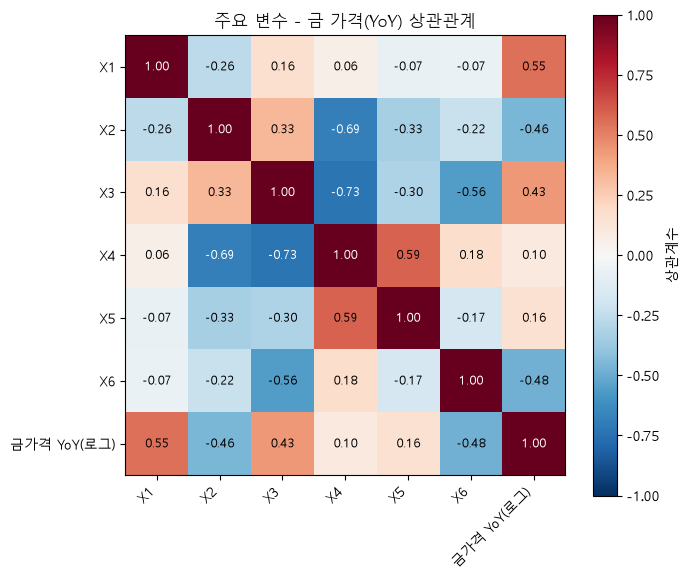

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

VARIABLE_LABELS = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
    Y: "금가격 YoY(로그)",
}

corr_cols = [*RAW_XCOLS, Y]
corr = d[corr_cols].corr()
labels = [VARIABLE_LABELS.get(c, c) for c in corr_cols]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.values[i, j]
        color = "white" if abs(value) > 0.6 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
ax.set_title("주요 변수 - 금 가격(YoY) 상관관계")
fig.colorbar(im, ax=ax, label="상관계수")
plt.tight_layout()
plt.show()

## 주요 변수 - 금 가격(레벨) 상관관계 히트맵

이번엔 YoY 로그 변화율이 아니라 금 가격 **레벨 자체**(`gold`)와 6개 주요 변수의 상관계수다.

> **주의**: 금 가격 레벨은 계속 우상향하는 추세 데이터라서, 마찬가지로 추세가 있는 변수와는
> 실제 관계가 없어도 상관계수가 높게(또는 반대로) 나올 수 있다(가성 상관). 위쪽 YoY 로그
> 히트맵이 모델이 실제로 보는 관계이고, 이 히트맵은 비교/참고용이다.

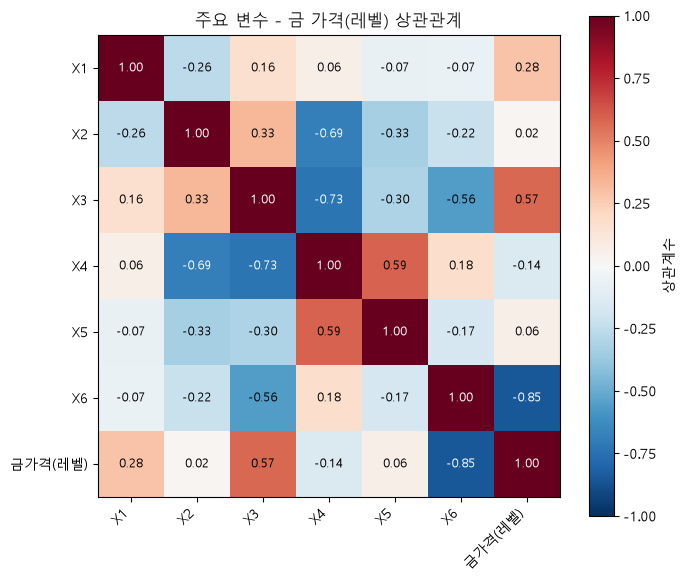

In [11]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

VARIABLE_LABELS_LEVEL = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
    "gold": "금가격(레벨)",
}

d_level = d.merge(df[["quarter", "gold"]], on="quarter", how="left")
corr_cols_level = [*RAW_XCOLS, "gold"]
corr_level = d_level[corr_cols_level].corr()
labels_level = [VARIABLE_LABELS_LEVEL.get(c, c) for c in corr_cols_level]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_level.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels_level)))
ax.set_yticks(range(len(labels_level)))
ax.set_xticklabels(labels_level, rotation=45, ha="right")
ax.set_yticklabels(labels_level)
for i in range(len(labels_level)):
    for j in range(len(labels_level)):
        value = corr_level.values[i, j]
        color = "white" if abs(value) > 0.6 else "black"
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
ax.set_title("주요 변수 - 금 가격(레벨) 상관관계")
fig.colorbar(im, ax=ax, label="상관계수")
plt.tight_layout()
plt.show()